# Press Start: What 36,000 Steam games reveal about Indie success
**Exploratory Data Analysis** · Faisal Mohammed Al-Fifi · Prince Sattam bin Abdulaziz University

**Dataset:** [Steam Games Dataset, Artemiy Ermilov (Kaggle, March 2025 snapshot)](https://www.kaggle.com/datasets/artermiloff/steam-games-dataset)

## 1. Problem Definition
**What is the dataset about?** About 95,000 apps on the Steam store, with price, release date, genres, player tags,
review counts, playtime, languages and platforms, collected in March 2025.

**Persona.** A small Indie developer with a limited budget who will launch on Steam.

**Main questions**
1. Are Indie games less likely to become hits than non-Indie games?
2. Which genres and sub-genres give Indie games better odds compared with how crowded they are?
3. Does a high player rating guarantee visibility?
4. Which product choices are associated with Indie hits?

**Expected insights.** Most new games are Indie and most get little attention; crowded genres offer worse odds;
a good rating alone is not enough.

**Hit (target).** A game is a *hit* if its review count is in the **top 5% of games released in the same year**.
Reviews measure visibility, not sales.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "games_march2025_full.csv"
CLEAN = ROOT / "data" / "processed" / "clean_data.csv"

# Project colours (same as the dashboard)
BG, PANEL, TEXT, MUTED, GRID = "#1e2140", "#2a2e57", "#f4f1de", "#b8b5d6", "#3a3f6e"
INDIE, OTHER, BLUE, ORANGE, GRAY = "#9f7aea", "#22a884", "#3b8fe0", "#e8663d", "#7c809e"
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": TEXT,
    "text.color": TEXT, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 100,
})
pd.set_option("display.max_columns", 50)

## 2. Data Loading & Structure (original file, unmodified)

In [2]:
raw = pd.read_csv(RAW, low_memory=False)
raw.head()

,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,header_image,website,support_url,support_email,windows,mac,linux,metacritic_score,metacritic_url,achievements,recommendations,notes,supported_languages,full_audio_languages,packages,developers,publishers,categories,genres,screenshots,movies,user_score,score_rank,positive,negative,estimated_owners,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.00,1,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",NaN,https://shared.akamai.steamstatic.com/store_it...,http://counter-strike.net/,NaN,NaN,True,False,True,0,NaN,1,4401572,Includes intense violence and blood.,"['Czech', 'Danish', 'Dutch', 'English', 'Finni...","['English', 'Indonesian']","[{'title': 'Buy Counter-Strike 2', 'descriptio...",['Valve'],['Valve'],"['Multi-player', 'Cross-Platform Multiplayer',...","['Action', 'Free To Play']",['https://shared.akamai.steamstatic.com/store_...,['http://video.akamai.steamstatic.com/store_tr...,0,NaN,7480813,1135108,100000000 - 200000000,33189,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.00,0,"LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...","LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...",Play PUBG: BATTLEGROUNDS for free. Land on str...,NaN,https://shared.akamai.steamstatic.com/store_it...,https://www.pubg.com,https://support.pubg.com/hc/en-us,NaN,True,False,False,0,NaN,37,1732007,NaN,"['English', 'Korean', 'Simplified Chinese', 'F...",[],[],['PUBG Corporation'],"['KRAFTON, Inc.']","['Multi-player', 'PvP', 'Online PvP', 'Stats',...","['Action', 'Adventure', 'Massively Multiplayer...",['https://shared.akamai.steamstatic.com/store_...,[],0,NaN,1487960,1024436,50000000 - 100000000,0,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.00,2,"The most-played game on Steam. Every day, mill...","The most-played game on Steam. Every day, mill...","Every day, millions of players worldwide enter...",“A modern multiplayer masterpiece.” 9.5/10 – D...,https://shared.akamai.steamstatic.com/store_it...,http://www.dota2.com/,NaN,NaN,True,True,True,90,https://www.metacritic.com/game/pc/dota-2?ftag...,0,14337,"Dota 2 includes fantasy violence, use of alcoh...","['Bulgarian', 'Czech', 'Danish', 'Dutch', 'Eng...","['English', 'Korean', 'Simplified Chinese', 'V...","[{'title': 'Buy Dota 2', 'description': '', 's...",['Valve'],['Valve'],"['Multi-player', 'Co-op', 'Steam Trading Cards...","['Action', 'Strategy', 'Free To Play']",['https://shared.akamai.steamstatic.com/store_...,['http://video.akamai.steamstatic.com/store_tr...,0,NaN,1998462,451338,200000000 - 500000000,43031,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366
3,271590,Grand Theft Auto V Legacy,2015-04-13,17,0.00,0,"When a young street hustler, a retired bank ro...","When a young street hustler, a retired bank ro...",Grand Theft Auto V for PC offers players the o...,NaN,https://shared.akamai.steamstatic.com/store_it...,https://www.rockstargames.com/V/,https://support.rockstargames.com,NaN,True,False,False,96,https://www.metacritic.com/game/pc/grand-theft...,77,1803063,NaN,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'Spanish - Latin America']","[{'title': 'Buy Shark Cash Cards', 'descriptio...",['Rockstar North'],['Rockstar Games'],"['Single-player', 'Multi-player', 'PvP', 'Onli...","['Action', 'Adventure']",['https://shared.akamai.steamstatic.com/store_...,['http://video.akamai.steamstatic.com/store_tr...,0,NaN,1719950,250012,50000000 - 100000000,19323,771,7101,74,0,117698,"{'Open World':

In [3]:
raw.shape

(94948, 47)

In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94948 entries, 0 to 94947
Data columns (total 47 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   appid                     94948 non-null  int64  
 1   name                      94946 non-null  object 
 2   release_date              94948 non-null  object 
 3   required_age              94948 non-null  int64  
 4   price                     94948 non-null  float64
 5   dlc_count                 94948 non-null  int64  
 6   detailed_description      89522 non-null  object 
 7   about_the_game            89499 non-null  object 
 8   short_description         89599 non-null  object 
 9   reviews                   10428 non-null  object 
 10  header_image              94948 non-null  object 
 11  website                   41194 non-null  object 
 12  support_url               44185 non-null  object 
 13  support_email             78848 non-null  object 
 14  window

In [5]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
appid,94948.0,1707530.53,926434.62,20.0,887337.50,1591145.00,2491702.50,3570420.00
required_age,94948.0,0.18,1.70,-1.0,0.00,0.00,0.00,21.00
price,94948.0,6.91,13.07,0.0,0.99,3.99,9.99,999.98
dlc_count,94948.0,0.56,14.92,0.0,0.00,0.00,0.00,3427.00
metacritic_score,94948.0,2.76,14.11,0.0,0.00,0.00,0.00,97.00
achievements,94948.0,19.54,159.80,0.0,0.00,2.00,19.00,9821.00
recommendations,94948.0,1022.21,22741.51,0.0,0.00,0.00,0.00,4401572.00
user_score,94948.0,0.03,1.57,0.0,0.00,0.00,0.00,100.00
score_rank,39.0,99.13,0.70,98.0,99.00,99.00,100.00,100.00
positive,94948.0,1217.90,30979.74,0.0,0.00,8.00,51.00,7480813.00


In [6]:
missing = raw.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "pct": (missing / len(raw) * 100).round(1)})

,missing,pct
score_rank,94909,100.0
metacritic_url,91372,96.2
reviews,84520,89.0
notes,78296,82.5
website,53754,56.6
support_url,50763,53.5
support_email,16100,17.0
about_the_game,5449,5.7
detailed_description,5426,5.7
short_description,5349,5.6


**Observations**
- 94,948 rows × 47 columns. Missing values are mostly in text and link columns we do not need.
- `genres`, `tags`, `categories` and `supported_languages` are lists stored as text.
- `isnull()` hides some problems, so we check them below.

In [7]:
nrt = raw["num_reviews_total"]
print("num_reviews_total = -1 :", (nrt == -1).sum(), f"({(nrt == -1).mean():.1%})")
print("Smallest real review count:", nrt[nrt > 0].min())
print("Playtest / beta builds:", raw["name"].str.contains(r"playtest|beta test|open beta", case=False, na=False).sum())

num_reviews_total = -1 : 39575 (41.7%)
Smallest real review count: 10
Playtest / beta builds: 5232


- **`-1` is not missing data:** the smallest real value is 10, and Steam shows no review summary below 10 reviews.
  So `-1` means *fewer than 10 reviews*.
- **Playtests** are not released games, and some show the review count of the main game.

## 3. Data Cleaning

Cleaning is done in `src/cleaning.py` (run `python -m src.cleaning`). Each step and its row count:

In [8]:
log = pd.read_csv(ROOT / "data" / "processed" / "cleaning_log.csv")
log[["step", "rows_before", "rows_after", "removed"]]

,step,rows_before,rows_after,removed
0,Raw file loaded,94948,94948,0
1,Remove test builds,94948,89701,5247
2,Remove software,89701,88665,1036
3,Remove adult content,88665,85162,3503
4,Remove duplicate appid,85162,85162,0
5,Remove duplicate editions,85162,84970,192
6,Remove invalid dates,84970,84970,0
7,Keep releases 2020–2024,84970,54159,30811


| Step | Why |
|---|---|
| Remove test builds | Playtests / betas are not released games |
| Remove software | Apps whose only genres are tools (Utilities, Video Production…) |
| Content filter | Content not suitable for this academic presentation |
| Remove duplicate editions | Several store pages sharing one review pool (e.g. Standard + Gold edition) |
| Keep releases 2020–2024 | Recent market; 2020–2023 is the study cohort, 2024 is a robustness check |

**Other decisions:** `-1` reviews → 0 and flagged `few_reviews`; rating is only kept from 10 reviews;
the SteamSpy `positive` / `negative` columns are not used because they disagree with Steam's own counts.

**New features:** `is_indie`, `price_band`, `genres_core`, `subgenres` (from player tags), `n_languages`,
`n_platforms`, `is_multiplayer`, `review_count`, `rating_pct`, and the target `is_hit`.

In [9]:
df = pd.read_csv(CLEAN, parse_dates=["release_date"])
df["price_band"] = pd.Categorical(df["price_band"], ["Free", "Under $5", "$5–10", "$10–20", "$20+"], ordered=True)
study = df[df["release_year"].between(2020, 2023)].copy()   # main study cohort
print("Clean data:", df.shape, "| Study cohort 2020–2023:", study.shape)
study[["name", "release_year", "price", "is_indie", "genres_core", "subgenres",
       "review_count", "rating_pct", "is_hit"]].head()

Clean data: (54159, 40) | Study cohort 2020–2023: (36689, 40)


,name,release_year,price,is_indie,genres_core,subgenres,review_count,rating_pct,is_hit
0,Borderlands Game of the Year,2023,29.99,False,Action|RPG,Shooter|Open World,18896,93.0,True
1,Grand Theft Auto IV: The Complete Edition,2020,6.99,False,Action|Adventure,Open World|Shooter,149489,82.0,True
2,Defense of the Oasis,2020,4.99,False,Casual|Strategy,Turn-Based Strategy,56,92.0,False
4,Warp Frontier,2021,14.99,True,Adventure,Point & Click|Detective,33,87.0,False
5,Desktop Dungeons,2023,14.99,True,Adventure|Casual|RPG|Strategy,Roguelike|Puzzle,1117,88.0,True


In [10]:
study.isnull().sum()[study.isnull().sum() > 0]

developer               3
developer_titles       80
genres_core          1458
subgenres           10468
rating_pct          15795
dtype: int64

Only `rating_pct` (empty below 10 reviews, by design) and a few unknown developers are left empty.

## 4. Univariate Analysis

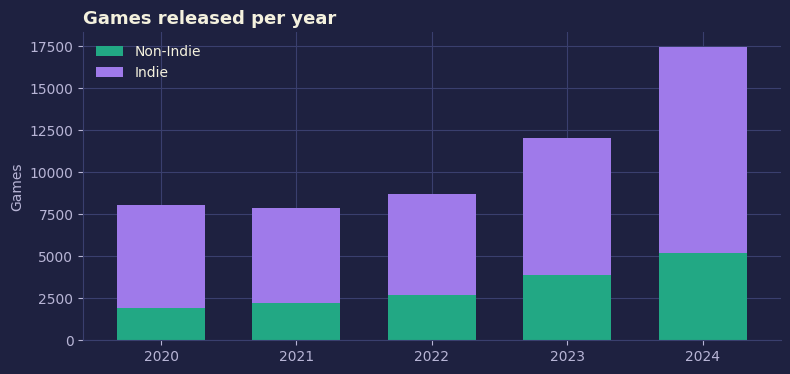

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
counts = df.groupby(["release_year", "is_indie"]).size().unstack()
counts.plot.bar(stacked=True, color=[OTHER, INDIE], ax=ax, width=0.65, rot=0)
ax.legend(["Non-Indie", "Indie"])
ax.set(title="Games released per year", xlabel="", ylabel="Games")
plt.show()

**Releases grow every year (≈8k in 2020 → ≈17.5k in 2024), and about 71% are Indie.** The market is getting more crowded.

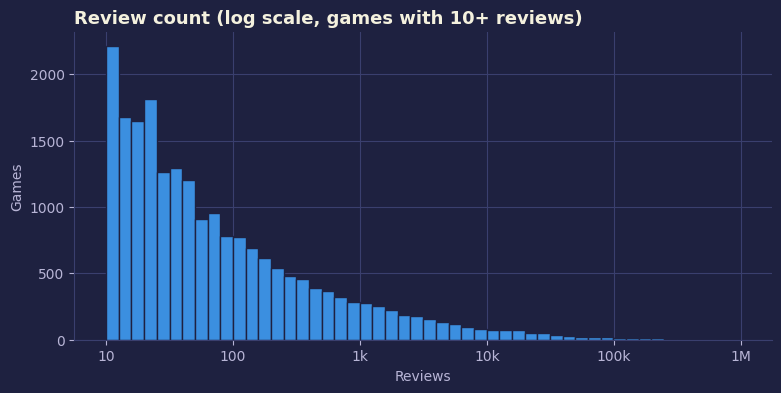

Games with fewer than 10 reviews: 43%


In [12]:
fig, ax = plt.subplots(figsize=(9, 4))
seen = study.loc[~study["few_reviews"], "review_count"]
ax.hist(np.log10(seen), bins=50, color=BLUE, edgecolor=BG)
ax.set_xticks([1, 2, 3, 4, 5, 6], ["10", "100", "1k", "10k", "100k", "1M"])
ax.set(title="Review count (log scale, games with 10+ reviews)", xlabel="Reviews", ylabel="Games")
plt.show()
print(f"Games with fewer than 10 reviews: {study['few_reviews'].mean():.0%}")

**Review counts are extremely right-skewed.** 43% of games never reach 10 reviews; a few giants have hundreds of thousands. Medians describe a typical game better than means.

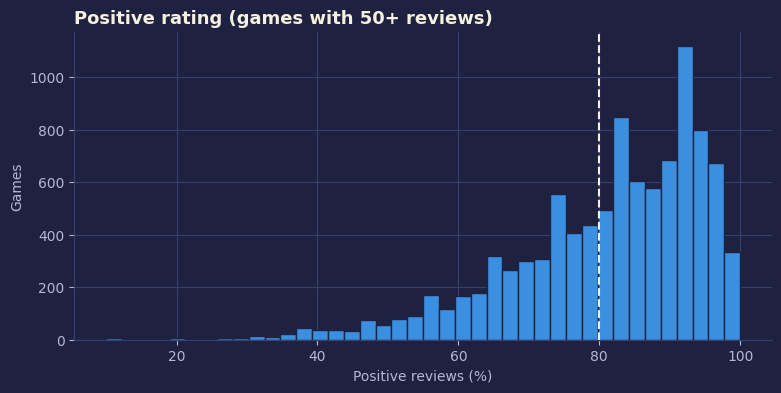

Median rating: 84.0


In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
rated = study[study["review_count"] >= 50]
ax.hist(rated["rating_pct"], bins=40, color=BLUE, edgecolor=BG)
ax.axvline(80, color=TEXT, ls="--")
ax.set(title="Positive rating (games with 50+ reviews)", xlabel="Positive reviews (%)", ylabel="Games")
plt.show()
print("Median rating:", rated["rating_pct"].median())

**Ratings skew high (median 84%).** Most games that get noticed are liked, so a good rating alone does not separate games much.

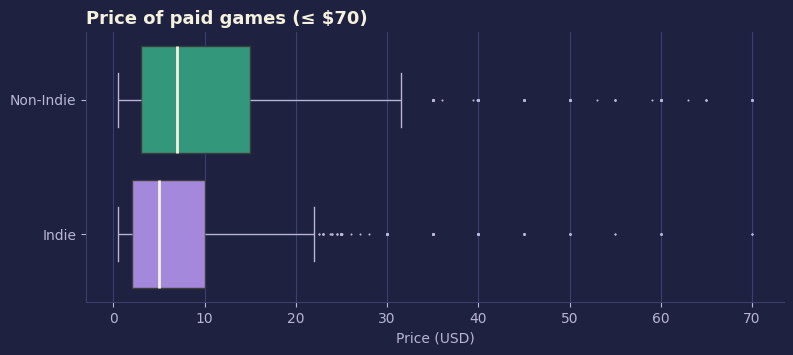

group
Indie        4.99
Non-Indie    6.99
Name: price, dtype: float64


In [14]:
fig, ax = plt.subplots(figsize=(9, 3.5))
paid = study[(study["price"] > 0) & (study["price"] <= 70)].assign(
    group=lambda d: d["is_indie"].map({True: "Indie", False: "Non-Indie"}))
sns.boxplot(data=paid, x="price", y="group", hue="group", palette={"Indie": INDIE, "Non-Indie": OTHER},
            legend=False, fliersize=1.5, ax=ax,
            medianprops={"color": TEXT, "linewidth": 2}, whiskerprops={"color": MUTED},
            capprops={"color": MUTED}, flierprops={"markerfacecolor": MUTED, "markeredgecolor": "none"})
ax.set(title="Price of paid games (≤ $70)", xlabel="Price (USD)", ylabel="")
plt.show()
print(paid.groupby("group")["price"].median())

**Indie games are cheaper** (median \$4.99 vs \$6.99). Points on the right are outliers: a few expensive games.

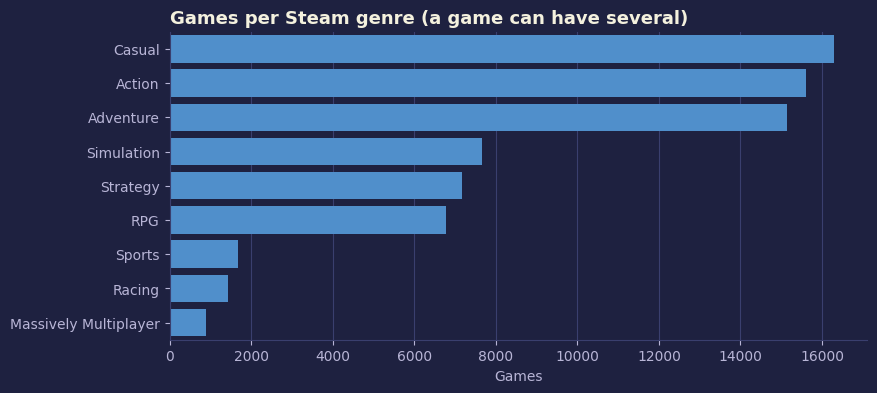

In [15]:
genres = study.assign(genre=study["genres_core"].fillna("").str.split("|")).explode("genre")
genres = genres[genres["genre"] != ""]
fig, ax = plt.subplots(figsize=(9, 4))
sns.countplot(data=genres, y="genre", order=genres["genre"].value_counts().index, color=BLUE, ax=ax)
ax.set(title="Games per Steam genre (a game can have several)", xlabel="Games", ylabel="")
plt.show()

**Casual, Action and Adventure are the most crowded genres.**

## 5. Bivariate & Multivariate Analysis

### Q1: Are Indie games less likely to become hits?

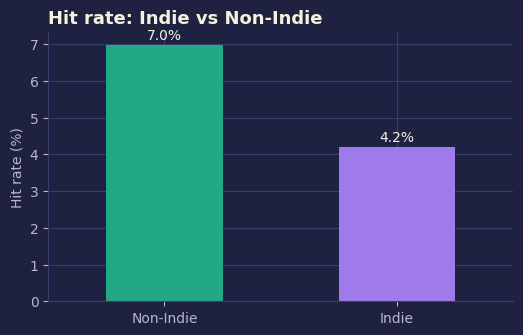

Indie share of games: 71% | Indie share of hits: 59%


In [16]:
rate = study.groupby("is_indie")["is_hit"].mean().mul(100).rename({True: "Indie", False: "Non-Indie"})
fig, ax = plt.subplots(figsize=(6, 3.5))
rate.plot.bar(color=[OTHER, INDIE], ax=ax, rot=0)
for i, v in enumerate(rate):
    ax.text(i, v + 0.15, f"{v:.1f}%", ha="center")
ax.set(title="Hit rate: Indie vs Non-Indie", ylabel="Hit rate (%)", xlabel="")
plt.show()
print(f"Indie share of games: {study['is_indie'].mean():.0%} | Indie share of hits: {study.loc[study['is_hit'], 'is_indie'].mean():.0%}")

**Indie games become hits 4.2% of the time vs 7.0% for non-Indie (≈40% lower).** They are 71% of games but only 59% of hits. The gap stays the same with a top-10% definition and for 2024 releases.

### Q2: Which genres give Indie games better odds?

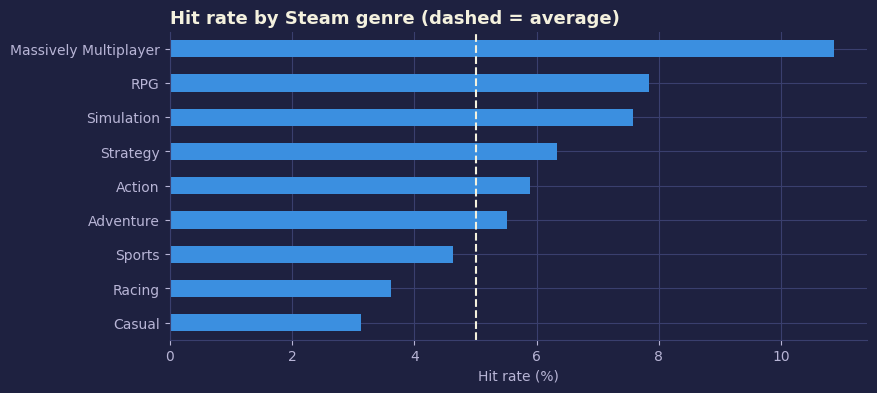

In [17]:
fig, ax = plt.subplots(figsize=(9, 4))
g_rate = genres.groupby("genre")["is_hit"].mean().mul(100).sort_values()
g_rate.plot.barh(color=BLUE, ax=ax)
ax.axvline(study["is_hit"].mean() * 100, color=TEXT, ls="--")
ax.set(title="Hit rate by Steam genre (dashed = average)", xlabel="Hit rate (%)", ylabel="")
plt.show()

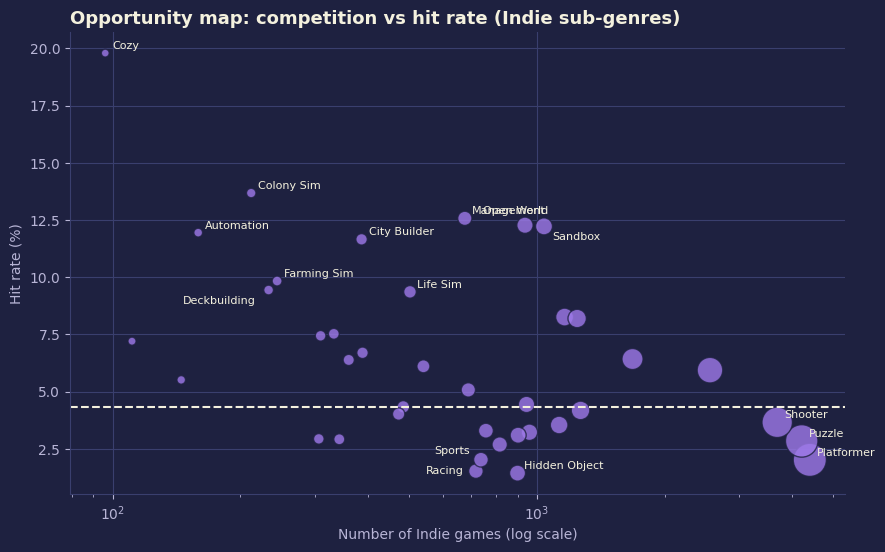

In [18]:
indie = study[study["is_indie"] & study["has_tags"]]
sub = indie.assign(sub=indie["subgenres"].fillna("").str.split("|")).explode("sub")
sub = sub[sub["sub"] != ""]
opp = sub.groupby("sub")["is_hit"].agg(games="size", hit_rate="mean").query("games >= 80")
opp["hit_rate"] *= 100

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(opp["games"], opp["hit_rate"], s=opp["games"] / 8 + 20, color=INDIE, alpha=0.8, edgecolor=BG)
nudge = {"Open World": (-30, 8), "Sandbox": (6, -10), "Deckbuilding": (-62, -10), "Racing": (-36, -2), "Sports": (-34, 4)}
for name, r in opp.iterrows():
    if r["hit_rate"] > 9 or r["hit_rate"] < 2.5 or r["games"] > 3000:
        ax.annotate(name, (r["games"], r["hit_rate"]), xytext=nudge.get(name, (5, 3)),
                    textcoords="offset points", fontsize=8)
ax.axhline(indie["is_hit"].mean() * 100, color=TEXT, ls="--")
ax.set_xscale("log")
ax.set(title="Opportunity map: competition vs hit rate (Indie sub-genres)",
       xlabel="Number of Indie games (log scale)", ylabel="Hit rate (%)")
plt.show()

**Casual, Racing and Sports have the lowest hit rates; RPG, Simulation and Massively Multiplayer the highest.**
Among Indie sub-genres, **Cozy, Colony Sim, Management, Open World and Sandbox** sit top-left (less competition, higher hit rate),
while **Platformer, Puzzle, Hidden Object, Racing and Sports** are crowded and below average.
A small niche can also mean small demand, so these are signals to investigate, not guarantees.

### Q3: Does a high rating guarantee visibility?

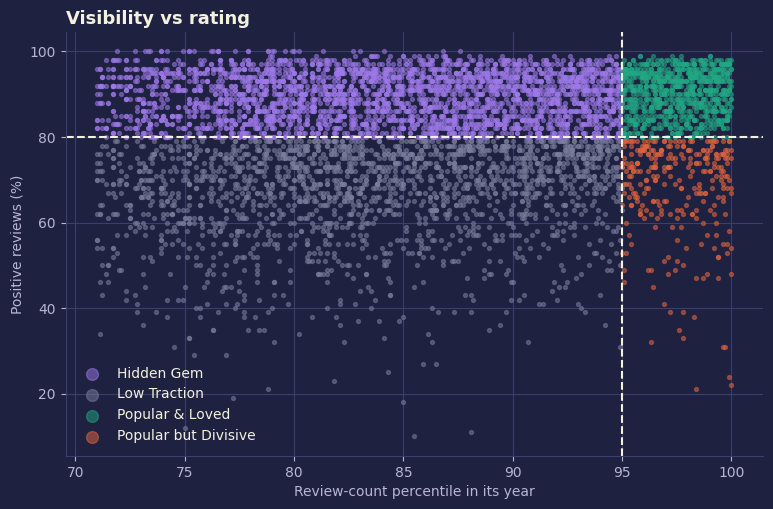

{'Hidden Gem': 4780, 'Low Traction': 3260, 'Popular & Loved': 1353, 'Popular but Divisive': 484} | Hidden Gems per Popular & Loved: 3.5


In [19]:
q = study[study["quadrant"] != "Not enough reviews"]
colors = {"Popular & Loved": OTHER, "Popular but Divisive": ORANGE, "Hidden Gem": INDIE, "Low Traction": GRAY}
fig, ax = plt.subplots(figsize=(9, 5.5))
for name, part in q.sample(6000, random_state=42).groupby("quadrant"):
    ax.scatter(part["visibility_pctile"], part["rating_pct"], s=8, alpha=0.5, color=colors[name], label=name)
ax.axvline(95, color=TEXT, ls="--"); ax.axhline(80, color=TEXT, ls="--")
ax.set(title="Visibility vs rating", xlabel="Review-count percentile in its year", ylabel="Positive reviews (%)")
ax.legend(loc="lower left", markerscale=3)
plt.show()
counts = q["quadrant"].value_counts()
print(counts.to_dict(), "| Hidden Gems per Popular & Loved:", round(counts["Hidden Gem"] / counts["Popular & Loved"], 1))

**No.** For every *Popular & Loved* game there are about **3.5 Hidden Gems**: rated 80%+ but never in the top 5% of visibility.

### Q4: Which choices are associated with Indie hits?

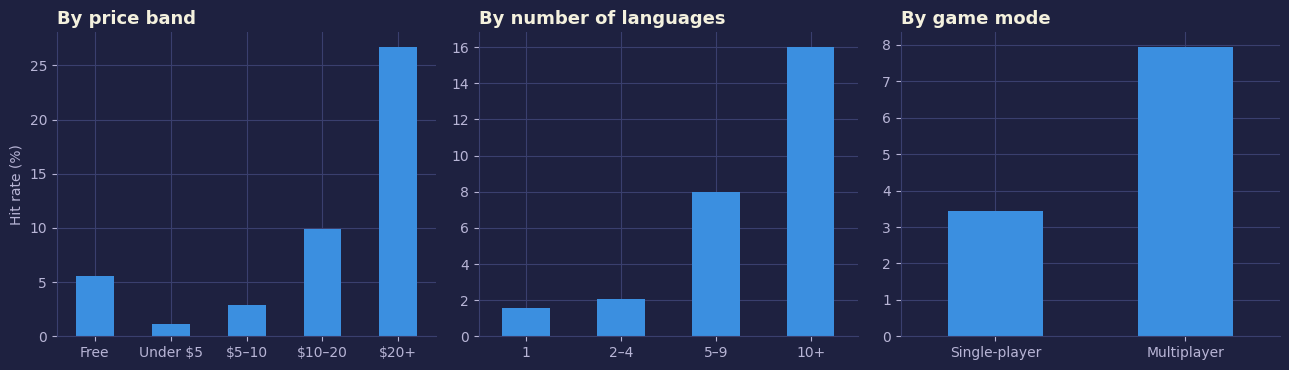

In [20]:
ind = study[study["is_indie"]]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ind.groupby("price_band", observed=True)["is_hit"].mean().mul(100).plot.bar(color=BLUE, ax=axes[0], rot=0)
axes[0].set(title="By price band", xlabel="", ylabel="Hit rate (%)")
pd.cut(ind["n_languages"], [0, 1, 4, 9, 200], labels=["1", "2–4", "5–9", "10+"]) \
    .pipe(lambda b: ind.groupby(b, observed=True)["is_hit"].mean().mul(100)) \
    .plot.bar(color=BLUE, ax=axes[1], rot=0)
axes[1].set(title="By number of languages", xlabel="", ylabel="")
ind.groupby("is_multiplayer")["is_hit"].mean().mul(100).rename({True: "Multiplayer", False: "Single-player"}) \
    .plot.bar(color=BLUE, ax=axes[2], rot=0)
axes[2].set(title="By game mode", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

**Higher price bands, more languages and multiplayer are all associated with more hits.**
These are associations, not causes: price stands for budget and scope, and successful games often add languages after launch.

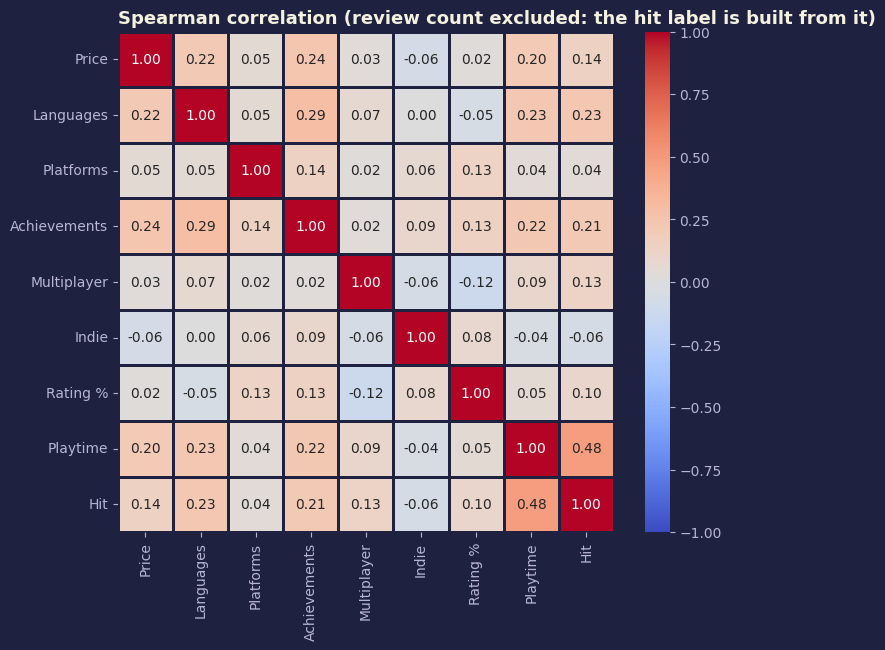

In [21]:
cols = {"price": "Price", "n_languages": "Languages", "n_platforms": "Platforms", "achievements": "Achievements",
        "is_multiplayer": "Multiplayer", "is_indie": "Indie", "rating_pct": "Rating %",
        "playtime_hours": "Playtime", "is_hit": "Hit"}
corr = study[list(cols)].astype(float).rename(columns=cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=1, linecolor=BG, ax=ax)
ax.set_title("Spearman correlation (review count excluded: the hit label is built from it)")
plt.show()

**Hit is most related to playtime (0.48), languages (0.23) and achievements (0.21).** Price and rating are almost
unrelated (≈ 0.02). Spearman is used because the data is heavily skewed.

## 6. Predictive Model (bonus)

In [22]:
m = json.load(open(ROOT / "models" / "metrics.json"))
pd.Series({
    "Model": "Logistic regression (L2, calibrated)",
    "Features": ", ".join(m["features"]),
    "Train ROC-AUC": m["train_auc"],
    "CV ROC-AUC (5-fold)": f"{m['cv_auc_mean']} ± {m['cv_auc_std']}",
    "Test ROC-AUC": m["test"]["roc_auc"],
    "Time check (2020–22 → 2023)": m["time_check"]["roc_auc"],
    "Hit rate in top 10% predicted": f"{m['test']['top10_hit_rate_pct']}% (base {m['test']['base_rate_pct']}%)",
}).to_frame("value")

,value
Model,"Logistic regression (L2, calibrated)"
Features,"n_platforms, is_indie, is_early_access, is_mul..."
Train ROC-AUC,0.839
CV ROC-AUC (5-fold),0.831 ± 0.009
Test ROC-AUC,0.838
Time check (2020–22 → 2023),0.824
Hit rate in top 10% predicted,24.8% (base 5.0%)


Only features known **before launch** are used (languages, reviews and playtime are excluded to avoid leakage).
Train and test ROC-AUC are equal (0.84), so the model does not overfit. ROC-AUC is used instead of accuracy because only 5% of games are hits.
Full training code: `src/model.py`.

## 7. Insights Summary
**Patterns**
- Steam is crowded and growing: ≈8k releases in 2020 → ≈17.5k in 2024, 71% Indie.
- Visibility is the main problem: 43% of games get fewer than 10 reviews.

**Relationships**
- Indie games become hits 4.2% of the time vs 7.0% for non-Indie.
- Systems-driven niches (Cozy, Colony Sim, Management) outperform crowded ones (Platformer, Puzzle, Hidden Object).
- Price, languages and multiplayer are associated with hits; price and rating are unrelated.

**Outliers**
- A few games have hundreds of thousands of reviews and very high prices or playtime; we use medians, log scales and Spearman.

**Key takeaways for a small Indie developer**
1. Plan for visibility, not only quality: there are 3.5 Hidden Gems for every Popular & Loved game.
2. Choose the genre carefully: less crowded, systems-driven niches show better odds.

## 8. Limitations & Future Work
- Reviews measure visibility, not sales or profit; owner counts are wide estimates.
- One snapshot (March 2025): prices and languages are current values, not launch values.
- "Indie" is a self-declared label; player tags are missing for some low-visibility games.
- Observational data: correlations, not causes.
- **Future:** track games from launch over time, add marketing data (wishlists, trailers), and analyse review text.